## 📓 Notebook 07: Model Comparison — Before vs. After

**Skills practiced:** Reusing one model and one split across stages, RMSE comparison, bar charts.

**Goal:** Retrain the same model at three stages (raw, cleaned/encoded/scaled, fully engineered) and chart the RMSE drop to prove feature engineering helped.

In [1]:
import pandas as pd
import joblib
import matplotlib.pyplot as plt

from sklearn.metrics import root_mean_squared_error

In [2]:
x_test1=pd.read_csv('../data/processed/stage_1/x_test.csv')
x_test2=pd.read_csv('../data/processed/stage_2/x_test_sc.csv')
x_test3=pd.read_csv('../data/processed/x_test.csv')
y_test=pd.read_csv('../data/processed/y_test.csv')

In [3]:
m1 = joblib.load('../models/stage1_model.joblib')
m2 = joblib.load('../models/stage2_model.joblib')
m3 = joblib.load('../models/stage3_model.joblib')

In [4]:
for name, (m, file) in {'s1': (m1, x_test1), 's2': (m2, x_test2), 's3': (m3, x_test3)}.items():
    extra = set(file.columns) - set(m.feature_names_in_)
    missing = set(m.feature_names_in_) - set(file.columns)
    print(name, 'extra:', extra, 'missing:', missing)

s1 extra: set() missing: set()
s2 extra: {'Unnamed: 0'} missing: set()
s3 extra: {'Unnamed: 0.2'} missing: set()


In [5]:
x_test2 = x_test2.drop(columns='Unnamed: 0')
x_test3 = x_test3.drop(columns='Unnamed: 0.2')

In [6]:
rmse_dict = {}

for name, (m, file) in {
    'Stage 1: raw dataset': (m1, x_test1),
    'Stage 2: cleaned/encoded/scaled': (m2, x_test2),
    'Stage 3: fully engineered': (m3, x_test3),
}.items():
    RMSE = round(root_mean_squared_error(y_test['cnt'], m.predict(file)), 2)
    print(name, RMSE)
    rmse_dict[name] = RMSE

Stage 1: raw dataset 251.08
Stage 2: cleaned/encoded/scaled 1239.88
Stage 3: fully engineered 298.34


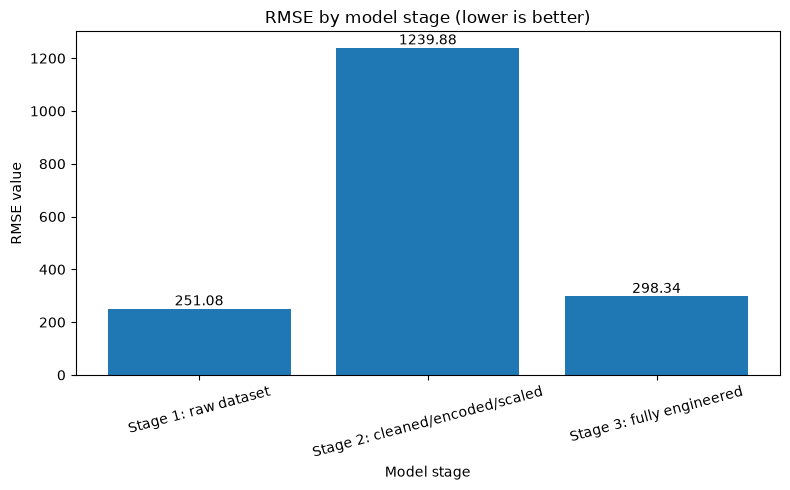

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(list(rmse_dict.keys()), list(rmse_dict.values()))
ax.bar_label(bars)

ax.set_xlabel('Model stage')
ax.set_ylabel('RMSE value')
ax.set_title('RMSE by model stage (lower is better)')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()